# 新文章：GBD 2023与UN WPP 2024比较基准研究

以2026-10-25 SubmissionPrep_XX新稿为准，NSFG不纳入此稿。使用19国、1990—2023年、女性15—49岁的真实原始输入。

本Notebook含完整分析代码，不依赖项目内其他脚本。由同版GBD人数和人口重建率，仅用UN人口替换参照18国年龄内人口份额。所有派生GBD结果为点估计，没有联合draws区间。

从项目根目录启动JupyterLab，然后依次执行所有单元。输入已存data/input；软件安装说明在README_先读我.md。

## 完整计算

先核验原始输入散列、维度、原发继发可加性及官方端点Rate，再计算动态/固定/等权参照、对称分解、逐国剔除与年度链式分解，并与既有新稿结果核对。

In [1]:
#!/usr/bin/env python3
"""完整核心复现：GBD 2023 + UN WPP 2024 比较基准分析。

运行：python code/PCOS_NewArticle_complete.py
输入为真实下载的原始GBD表与UN人口子集。此文件无需导入项目内其他代码。
不重新估计上游GBD模型，不生成伪造draws，不计算未经传播的GBD置信区间。
"""
from pathlib import Path
from itertools import product
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

AGES=list(range(15,50,5)); YEARS=list(range(1990,2024))
COUNTRIES=['Argentina','Australia','Brazil','Canada','China','France','Germany','India','Indonesia','Italy','Japan','Mexico','Republic of Korea','Russian Federation','Saudi Arabia','South Africa','Türkiye','United Kingdom','United States of America']
CAUSES=['Endometriosis','Polycystic ovarian syndrome']; TYPES=['Primary','Secondary','Total']

def digest(p): return hashlib.sha256(p.read_bytes()).hexdigest()

def main(root=None, output=None):
    root=Path(root) if root else (Path(__file__).resolve().parents[1] if '__file__' in globals() else Path.cwd())
    inputs=root/'data/input'; out=Path(output) if output else root/'results/python'
    out.mkdir(parents=True,exist_ok=True)
    prior=json.loads((root/'data/published_expected/qc_summary.json').read_text())
    for name,sha in prior['GBD_source_SHA256'].items():
        assert digest(inputs/name)==sha, 'GBD input SHA-256 mismatch: '+name
    unfile=inputs/'UN_WPP2024_G20_female_15_49_1990_2023.csv'
    assert digest(unfile)==prior['WPP_subset_SHA256'], 'UN subset SHA-256 mismatch'
    total=pd.read_csv(inputs/'IHME-GBD_2023_DATA-1b13e337-1.csv')
    strata=pd.read_csv(inputs/'IHME-GBD_2023_DATA-416daf73-1.csv')
    pop=pd.read_csv(inputs/'IHME-GBD_2023_DATA-916826fb-1.csv')
    w=pd.read_csv(inputs/'weights.csv').weight.to_numpy(float); w=w/w.sum()
    assert len(w)==7 and np.isclose(w.sum(),1)
    pop=pop.rename(columns={'location_name':'country','val':'gbd_pop'})
    pop['age_start']=(pop.age_id-5)*5
    pop=pop[['country','year','age_start','gbd_pop']]
    un=pd.read_csv(unfile).rename(columns={'gbd_country':'country'})
    keys=['country','year','age_start']
    assert len(pop)==len(un)==4522 and not pop.duplicated(keys).any() and not un.duplicated(keys).any()
    assert set(pop.country)==set(un.country)==set(COUNTRIES)
    pop=pop.merge(un[keys+['un_female_pop']],on=keys,validate='1:1')
    assert len(pop)==4522 and (pop[['gbd_pop','un_female_pop']]>0).all().all()
    a=total.query('measure_id==5 and metric_id==1 and rei_id==198 and sex_id==2').copy();a['subtype']='Total'
    b=strata.query('measure_id==5 and metric_id==1 and rei_id in [220,221] and sex_id==2').copy();b['subtype']=b.rei_id.map({220:'Primary',221:'Secondary'})
    d=pd.concat([a,b],ignore_index=True).rename(columns={'location_name':'country','cause_name':'cause','val':'gbd_cases'})
    d['age_start']=(d.age_id-5)*5
    assert len(d)==27132 and not d.duplicated(keys+['cause','subtype']).any()
    assert set(d.cause)==set(CAUSES) and set(d.subtype)==set(TYPES)
    cells=d[keys+['cause','subtype','gbd_cases']].merge(pop,on=keys,validate='m:1')
    assert len(cells)==27132 and np.isfinite(cells.gbd_cases).all() and (cells.gbd_cases>=0).all()
    cells['gbd_rate']=100000*cells.gbd_cases/cells.gbd_pop
    sums=cells.pivot(index=keys+['cause'],columns='subtype',values='gbd_cases')
    additive=float(abs(sums.Total-sums.Primary-sums.Secondary).max()); assert additive<1e-6
    # 原始端点Rate独立检查，避免仅在重建率内部自我核对。
    e=pd.read_csv(inputs/'IHME-GBD_2023_DATA-76c5523c-1.csv')
    e=e.query('measure_id==5 and metric_id==3 and sex_id==2 and rei_id in [220,221]').copy()
    e['subtype']=e.rei_id.map({220:'Primary',221:'Secondary'});e['age_start']=(e.age_id-5)*5
    e=e.rename(columns={'location_name':'country','cause_name':'cause','val':'official_rate'})
    ep=e.merge(cells,on=keys+['cause','subtype'],validate='1:1')
    endpoint_error=float(abs(ep.official_rate-ep.gbd_rate).max());assert len(ep)==1064 and endpoint_error<1e-8
    refs=sorted(set(COUNTRIES)-{'China'})
    idx=pd.MultiIndex.from_product([refs,AGES,YEARS],names=['country','age_start','year'])
    pp=pop.set_index(['country','age_start','year']).reindex(idx)
    shares={}
    for source,col in [('GBD','gbd_pop'),('UN-WPP2024','un_female_pop')]:
        p=pp[col].to_numpy().reshape(18,7,34);s=p/p.sum(axis=0,keepdims=True)
        assert np.allclose(s.sum(axis=0),1,atol=1e-12,rtol=0);shares[source]=s
    annual=[]; decomp=[]; loo=[]; chained=[]
    for cause,subtype in product(CAUSES,TYPES):
        z=cells[(cells.cause==cause)&(cells.subtype==subtype)]
        rr=z.set_index(['country','age_start','year']).reindex(idx).gbd_rate.to_numpy().reshape(18,7,34)
        cc=z[z.country=='China'].set_index(['age_start','year']).reindex(pd.MultiIndex.from_product([AGES,YEARS])).gbd_rate.to_numpy().reshape(7,34)
        assert np.isfinite(rr).all() and np.isfinite(cc).all()
        cr=(w[:,None]*cc).sum(axis=0)
        for source,s in shares.items():
            for bench,ss in [('dynamic',s),('fixed1990',np.broadcast_to(s[:,:,[0]],s.shape)),('equal',np.full_like(s,1/18))]:
                ar=(w[:,None]*(ss*rr).sum(axis=0)).sum(axis=0)
                for j,year in enumerate(YEARS):
                    annual.append(dict(cause=cause,subtype=subtype,source=source,year=year,benchmark=bench,china_aspr=cr[j],ref_aspr=ar[j],gap=cr[j]-ar[j],ratio=cr[j]/ar[j]))
            for end in [2021,2022,2023]:
                j=YEARS.index(end);r0=rr[:,:,0];r1=rr[:,:,j];s0=s[:,:,0];s1=s[:,:,j]
                initial=cr[0]-(w*(s0*r0).sum(axis=0)).sum();last=cr[j]-(w*(s1*r1).sum(axis=0)).sum()
                x=cr[j]-cr[0];q=-(w*((s0+s1)/2*(r1-r0)).sum(axis=0)).sum();sc=-(w*((r0+r1)/2*(s1-s0)).sum(axis=0)).sum();net=last-initial
                assert abs(x+q+sc-net)<1e-8
                decomp.append(dict(cause=cause,subtype=subtype,source=source,end=end,initial_gap=initial,end_gap=last,net_gap_change=net,china_rate_effect=x,reference_rate_effect=q,reference_country_composition_effect=sc,composition_share_of_net=sc/net if abs(net)>1e-10 else np.nan))
            x=cr[-1]-cr[0];q=-(w[None,:,None]*(s[:,:,1:]+s[:,:,:-1])/2*(rr[:,:,1:]-rr[:,:,:-1])).sum();sc=-(w[None,:,None]*(rr[:,:,1:]+rr[:,:,:-1])/2*(s[:,:,1:]-s[:,:,:-1])).sum()
            assert abs(x+q+sc-(decomp[-1]['net_gap_change']))<1e-8
            chained.append(dict(cause=cause,subtype=subtype,source=source,china_rate_effect=x,reference_rate_effect=q,reference_country_composition_effect=sc,net_gap_change=x+q+sc,composition_share_of_net=sc/(x+q+sc)))
            for k,country in enumerate(refs):
                ss=s.copy();ss[k]=0;ss=ss/ss.sum(axis=0,keepdims=True)
                ar=(w[:,None]*(ss*rr).sum(axis=0)).sum(axis=0);gap=cr-ar
                loo.append(dict(cause=cause,subtype=subtype,source=source,omitted_country=country,initial_gap=gap[0],gap_2023=gap[-1],change=gap[-1]-gap[0]))
    frames={'all_annual_benchmark_aspr':pd.DataFrame(annual),'symmetric_decomposition_1990_endpoints':pd.DataFrame(decomp),'leave_one_country_out':pd.DataFrame(loo),'annual_chained_decomposition':pd.DataFrame(chained)}
    # 按研究新版本既有结果逐项核对，支持独立复算而非抄录固定数字。
    comparison={}
    for name,keys2 in [('all_annual_benchmark_aspr',['cause','subtype','source','year','benchmark']),('symmetric_decomposition_1990_endpoints',['cause','subtype','source','end']),('leave_one_country_out',['cause','subtype','source','omitted_country'])]:
        expected=pd.read_csv(root/'data/published_expected'/f'{name}.csv').set_index(keys2).sort_index();got=frames[name].set_index(keys2).sort_index()
        assert expected.index.equals(got.index)
        diff=float(np.nanmax(abs(expected.select_dtypes('number').to_numpy()-got[expected.select_dtypes('number').columns].to_numpy())))
        assert diff<1e-8,(name,diff);comparison[name]=dict(rows=len(got),max_absolute_difference=diff)
    tvd=abs(shares['GBD']-shares['UN-WPP2024']).sum(axis=0)/2
    frames['population_share_TVD']=pd.DataFrame([dict(age_start=a,year=y,total_variation_distance=tvd[i,j]) for i,a in enumerate(AGES) for j,y in enumerate(YEARS)])
    frames['rate_cells']=cells
    for name,frame in frames.items():frame.to_csv(out/f'{name}.csv',index=False)
    qc=dict(gbd_population_cells=len(pop),un_population_cells=len(un),disease_rate_cells=len(cells),subtype_additivity_max_error=additive,official_endpoint_rate_max_error=endpoint_error,official_endpoint_rate_cells=len(ep),published_result_comparison=comparison,no_joint_draws=True,interpretation='GBD model point estimates; UN substitutes only within-age reference-country shares; no independent disease validation',python=sys.version)
    (out/'qc_summary.json').write_text(json.dumps(qc,indent=2))
    render_figures(frames,out)
    print(json.dumps(qc,indent=2));return frames

def render_figures(frames,out):
    """真实数值科研图；图中不添加不存在的区间。"""
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'pdf.fonttype':42})
    a=frames['all_annual_benchmark_aspr'];d=frames['symmetric_decomposition_1990_endpoints']
    fig,ax=plt.subplots(figsize=(8,4.5))
    for source,color in [('GBD','#154e63'),('UN-WPP2024','#d97706')]:
        z=a[(a.cause=='Polycystic ovarian syndrome')&(a.subtype=='Total')&(a.source==source)&(a.benchmark=='dynamic')]
        ax.plot(z.year,z.gap,label=source,color=color,linewidth=2)
    ax.set(xlabel='Year',ylabel='China minus reference, per 100,000',title='PCOS total infertility: dynamic population shares');ax.legend();ax.spines[['top','right']].set_visible(False);fig.tight_layout();fig.savefig(out/'figure1_gap_trends.pdf');fig.savefig(out/'figure1_gap_trends.png',dpi=200);plt.close(fig)
    fig,ax=plt.subplots(figsize=(8,4.5));labels=['China rate','Reference rate','Reference composition']
    for k,source in enumerate(['GBD','UN-WPP2024']):
        z=d[(d.cause=='Polycystic ovarian syndrome')&(d.subtype=='Total')&(d.source==source)&(d.end==2023)].iloc[0]
        vals=[z.china_rate_effect,z.reference_rate_effect,z.reference_country_composition_effect];ax.bar(np.arange(3)+(k-.5)*.35,vals,width=.35,label=source,color=['#154e63','#d97706'][k])
    ax.axhline(0,color='#64748b',linewidth=.8);ax.set_xticks(range(3),labels);ax.set(ylabel='Component, per 100,000',title='1990–2023 symmetric decomposition');ax.legend();fig.tight_layout();fig.savefig(out/'figure2_decomposition.pdf');fig.savefig(out/'figure2_decomposition.png',dpi=200);plt.close(fig)
    fig,ax=plt.subplots(figsize=(8,4.5));z=a[(a.cause=='Polycystic ovarian syndrome')&(a.subtype=='Secondary')&(a.source=='UN-WPP2024')&(a.year==2023)].set_index('benchmark');benches=['dynamic','fixed1990','equal'];vals=z.loc[benches].gap
    bars=ax.barh(['Contemporary UN shares','Fixed 1990 UN shares','Equal country weights'],vals,color=['#d97706','#154e63','#64748b']);ax.bar_label(bars,fmt='%.2f',padding=4);ax.axvline(0,color='#94a3b8');ax.set(xlabel='China minus reference, per 100,000',xlim=(-150,35),title='PCOS secondary infertility, 2023');fig.tight_layout();fig.savefig(out/'figure3_benchmark_sensitivity.pdf');fig.savefig(out/'figure3_benchmark_sensitivity.png',dpi=200);plt.close(fig)
    fig,ax=plt.subplots(figsize=(8,4.5));z=a[(a.cause=='Endometriosis')&(a.subtype=='Total')&(a.source=='GBD')&(a.benchmark=='dynamic')];ax.plot(z.year,z.gap,color='#154e63',linewidth=2);ax.axhline(0,color='#94a3b8',linewidth=.8);ax.set(xlabel='Year',ylabel='China minus reference, per 100,000',title='Endometriosis: endpoint sensitivity');fig.tight_layout();fig.savefig(out/'figure4_endometriosis.pdf');fig.savefig(out/'figure4_endometriosis.png',dpi=200);plt.close(fig)

analysis_results = main(root=Path.cwd(), output=Path.cwd()/'results/notebook_python')


{
  "gbd_population_cells": 4522,
  "un_population_cells": 4522,
  "disease_rate_cells": 27132,
  "subtype_additivity_max_error": 5.820766091346741e-10,
  "official_endpoint_rate_max_error": 1.1596057447604835e-11,
  "official_endpoint_rate_cells": 1064,
  "published_result_comparison": {
    "all_annual_benchmark_aspr": {
      "rows": 1224,
      "max_absolute_difference": 3.410605131648481e-13
    },
    "symmetric_decomposition_1990_endpoints": {
      "rows": 36,
      "max_absolute_difference": 3.410605131648481e-13
    },
    "leave_one_country_out": {
      "rows": 216,
      "max_absolute_difference": 3.410605131648481e-13
    }
  },
  "no_joint_draws": true,
  "interpretation": "GBD model point estimates; UN substitutes only within-age reference-country shares; no independent disease validation",
  "python": "3.12.14 (main, Aug 25 2026, 13:50:33) [Clang 22.1.3 ]"
}


## 主要结果及图形

人口构成贡献在GBD/UN两套权重下分别为58.5%/57.6%。继发不孕率差会随参照基准改变正负号，不能把情景范围作为置信区间。

,cause,subtype,source,end,initial_gap,end_gap,net_gap_change,china_rate_effect,reference_rate_effect,reference_country_composition_effect,composition_share_of_net
32,Polycystic ovarian syndrome,Total,GBD,2023,-272.915220,-121.376216,151.539003,271.513723,-208.623253,88.648533,0.584988
35,Polycystic ovarian syndrome,Total,UN-WPP2024,2023,-273.312972,-122.621393,150.691579,271.513723,-207.585159,86.763015,0.575766


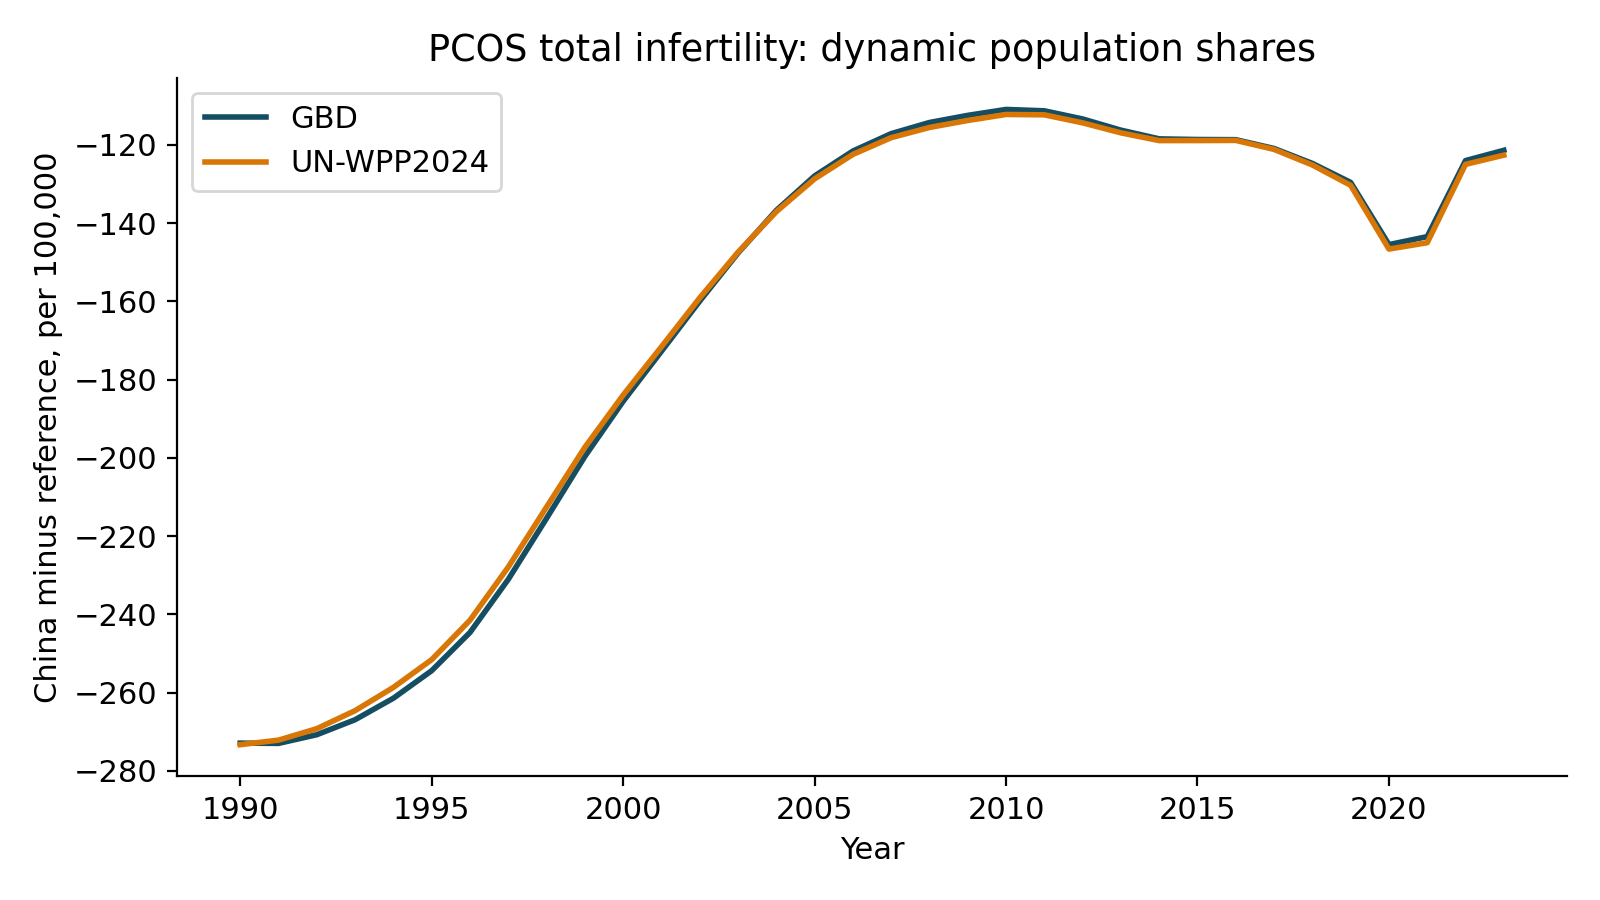

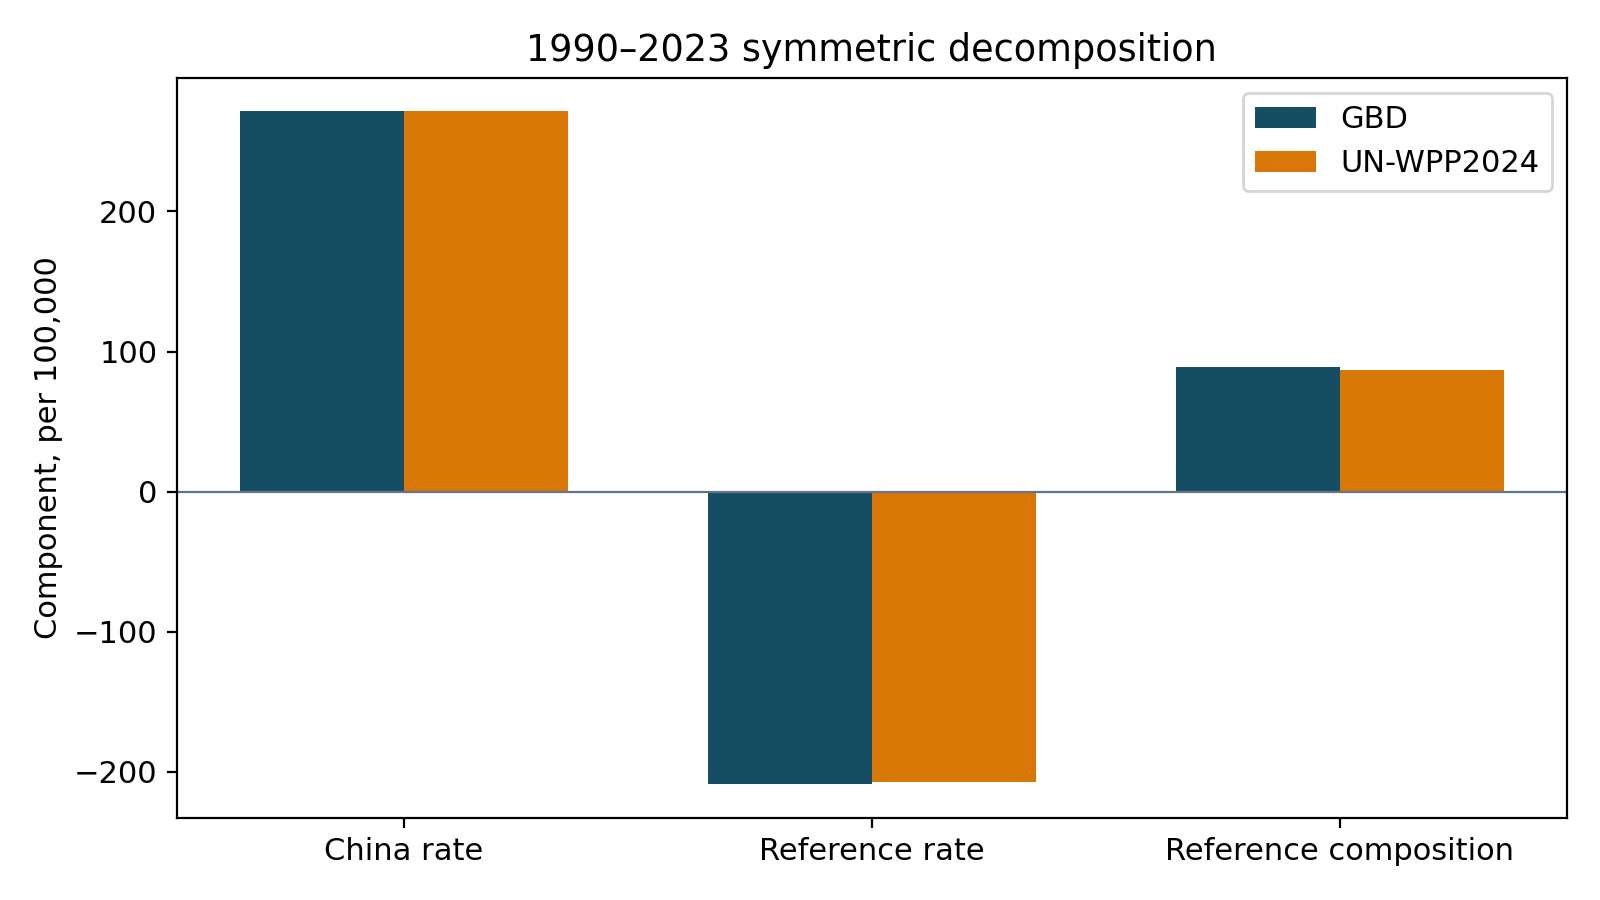

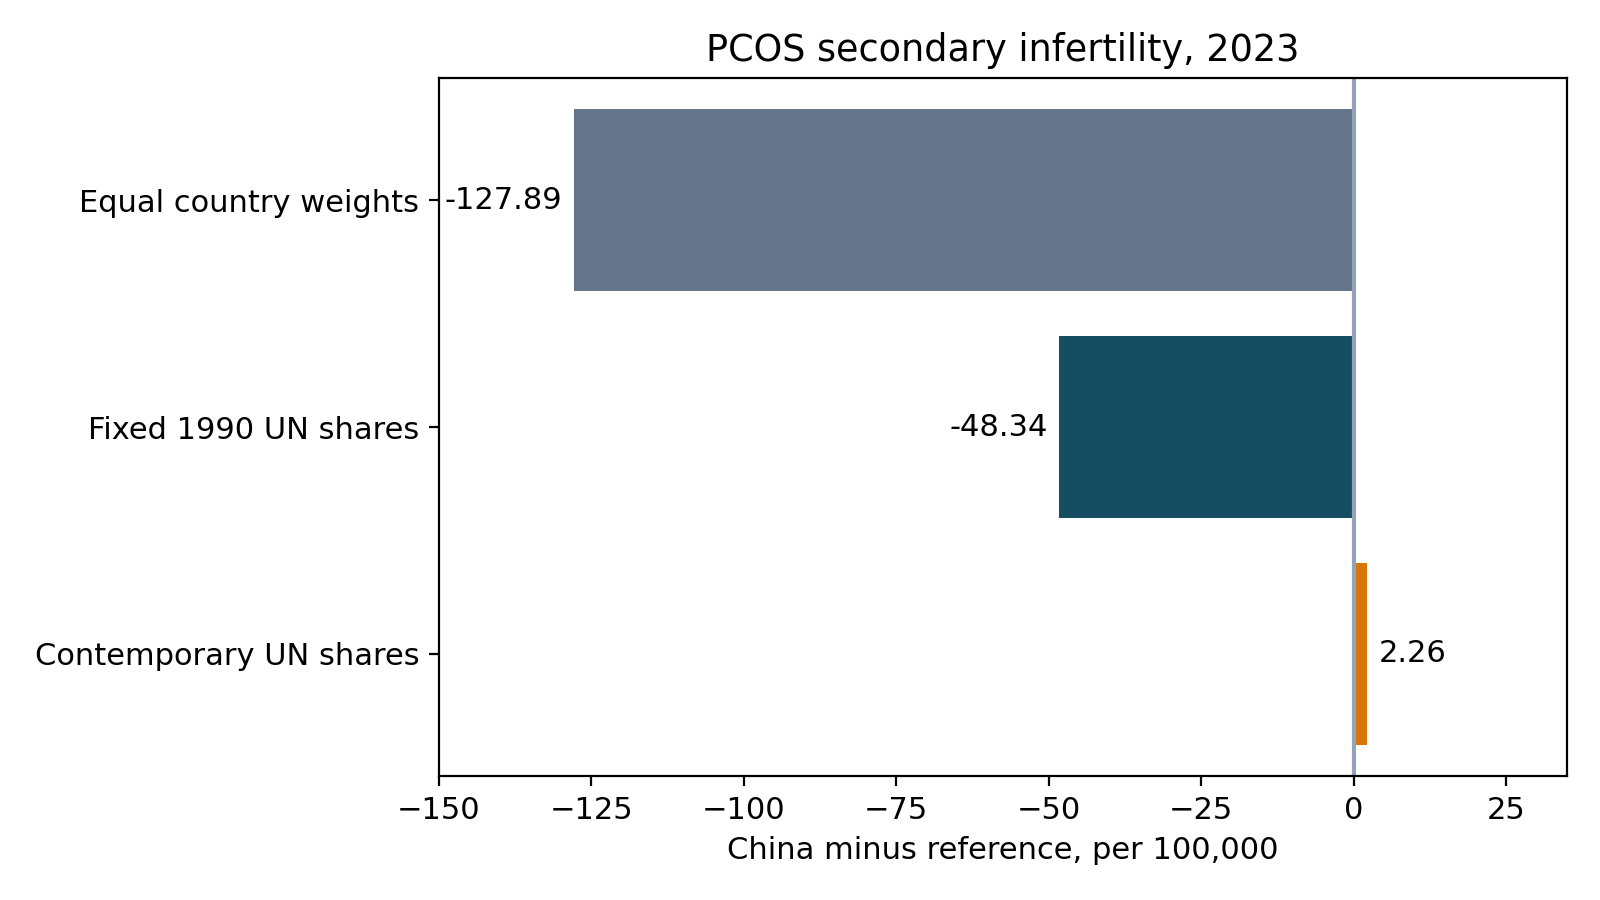

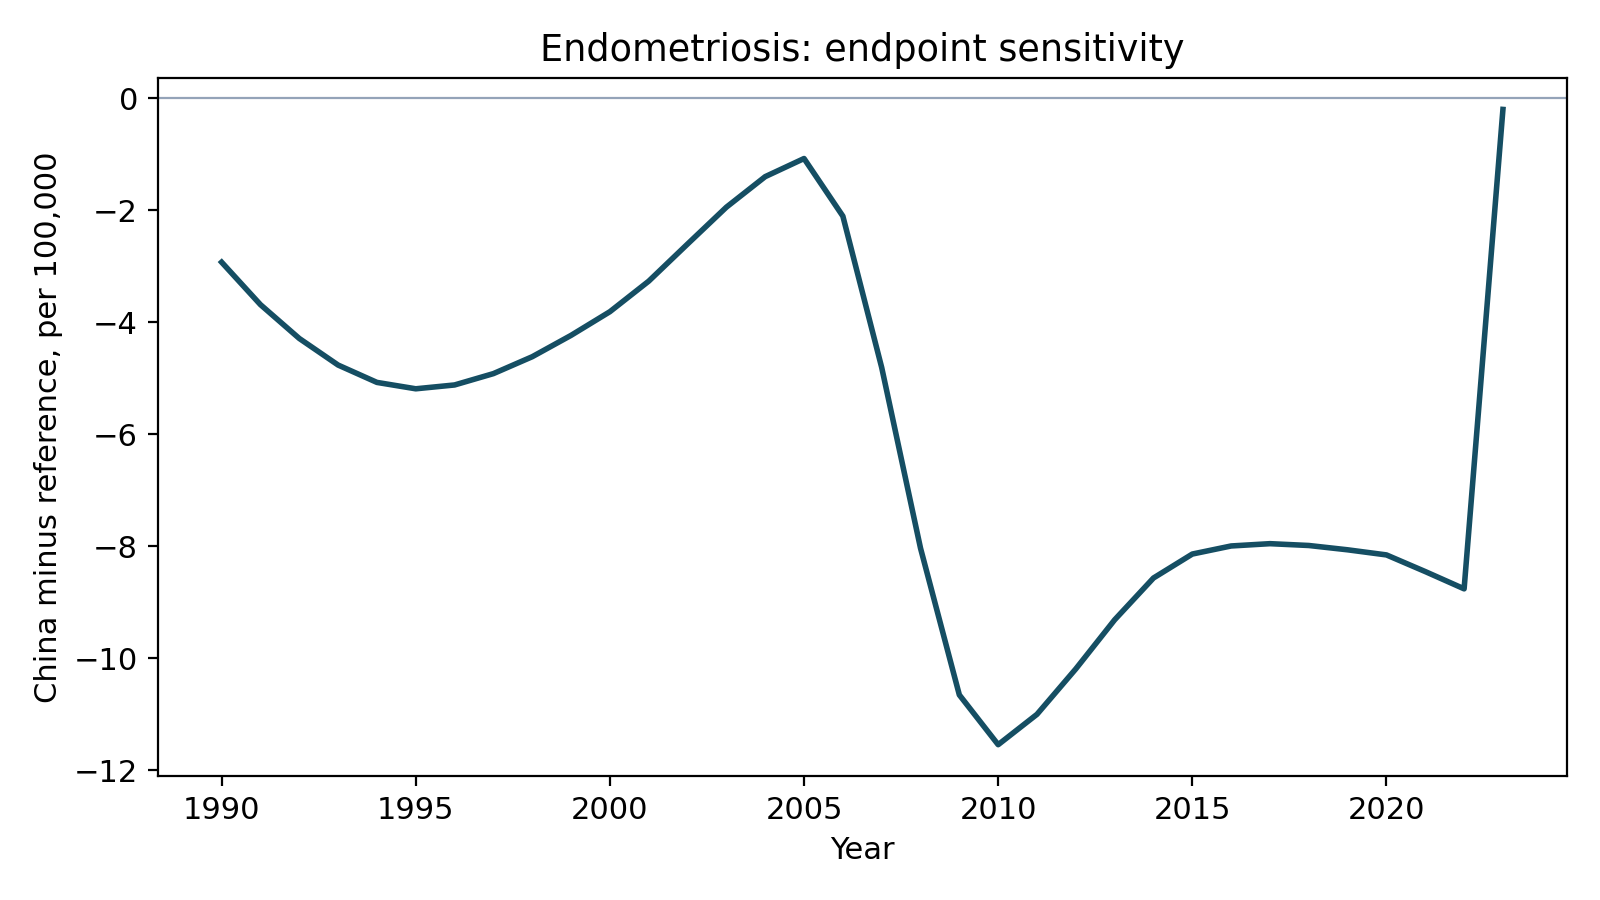

In [2]:
display(analysis_results['symmetric_decomposition_1990_endpoints'].query("cause=='Polycystic ovarian syndrome' and subtype=='Total' and end==2023"))
from IPython.display import Image, display
for f in ['figure1_gap_trends.png','figure2_decomposition.png','figure3_benchmark_sensitivity.png','figure4_endometriosis.png']:
    display(Image(filename=str(Path.cwd()/'results/notebook_python'/f)))